# Statistiques de prewid

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/prewid/prewid_stats.ipynb)

Présentation et analyse statistique du jeu, lues du point de vue de Tiny-YOLO et de la
cible embarquée (entrée 416, grilles 13×13 et 26×26, 256 emplacements de `yolo_post`,
INT8). Tâches : [T38.1](../../docs/tasks/M38-prewid.md), [T38.5](../../docs/tasks/M38-prewid.md), [T16.4](../../docs/tasks/M16-presentation-jeux.md) ; jalon : [M16](../../docs/tasks/M16-presentation-jeux.md) ;
synthèse : [stats-jeux.md](../../docs/tasks/stats-jeux.md). Autres notebooks du jeu :
[tiny-yolov2-voc_infer](tiny-yolov2-voc_infer.ipynb), [tiny-yolov3-coco_infer](tiny-yolov3-coco_infer.ipynb), [tiny-yolov4-coco_infer](tiny-yolov4-coco_infer.ipynb), [tiny-yolov7-coco_infer](tiny-yolov7-coco_infer.ipynb), [tiny-yolov3-prewid_infer](tiny-yolov3-prewid_infer.ipynb), [tiny-yolov3-prewid_train](tiny-yolov3-prewid_train.ipynb), [tiny-yolov3-prewid_sweep](tiny-yolov3-prewid_sweep.ipynb), [tiny-yolov4-prewid_infer](tiny-yolov4-prewid_infer.ipynb), [tiny-yolov4-prewid_train](tiny-yolov4-prewid_train.ipynb), [tiny-yolov4-prewid_sweep](tiny-yolov4-prewid_sweep.ipynb).

Palier : annotations **R** (split entier), pixels **M** (`SAMPLE = 200`
images par partie). Prérequis : données `data/prewid/annotations_val.json` — tools/get_datasets.sh prewid. Ni poids ni GPU.

Question propre : How far are the workers from each camera (box height per camera), and what share of the frames is empty? (renvoi : T38.3).

| | |
|---|---|
| source | https://data.mendeley.com/datasets/xgt8kyxyrz/1 (doi:10.17632/xgt8kyxyrz.1) |
| version | V1 (2026-06-03); split by tools/prep_datasets.py prewid |
| licence | CC BY 4.0. Attribution: J. Silvestre-Blanes, T. Albero-Albero, J. Zafrilla-Muñoz, R. Perez Llorens (2026), PREWID, Mendeley Data V1, Universitat Politècnica de València |
| capteur | fixed industrial IP cameras in a legacy plant (CAM0-CAM3), elevated view; one laboratory sequence (CAMLAB01) |
| résolution typique | 640×480 (plant), 1920×1080 (lab) |
| officiel `train` | — images, — objets |
| officiel `val` | — images, — objets |
| officiel `test` | — images, — objets |
| chargeur | no official split: per plant camera, empty frames and worker frames each cut by frame number into contiguous blocks 70 / 15 / 15 (worker cuts at a gap in the numbers); the lab sequence is its own `lab` split |
| chargeur | the readme says PNG grayscale; the files are colour JPEG |
| chargeur | frame names are counters, not times; frame rate not published |
| chargeur | leave-one-camera-out splits: `loco_<camera>_{train,val,test}` |

Aucun calcul ici : `tools/data_stats.py` calcule (`stats.json`, `stats.md`, galerie),
`tools/figures/donnees.py` trace ; chaque étape affiche la commande. Sorties dans
`build/notebooks/prewid/stats/`, jamais dans `results/`. Notebook généré par `python -m tools.notebooks`
(`make notebooks`) : modifier `tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [1]:
DATASET   = 'prewid'  # clé de DATASETS
SPLITS    = None  # liste de splits ; None : splits train puis test du jeu
SIZE      = None  # S ou 'LxH' ; None : entrée de la cfg du jeu (416 sinon)
RESIZE    = 'letterbox'  # letterbox | stretch (grandeurs vues par le réseau)
SAMPLE    = 200  # images lues pour les pixels, par partie ; 0 : aucune
GALLERY   = 8  # images de la galerie par split
SEED      = 0  # tirage des images (pixels, galerie, nuages)
NET       = 'build/m11/cfg/tiny-yolov3-prewid.cfg'  # cfg dont les ancres et grilles servent aux collisions
DEVICE    = 'cpu'  # noyau CPU : rien ne tourne sur GPU
DATA_ROOT = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar ; None : pas de Drive
OUT       = 'build/notebooks/prewid/stats'  # sorties du notebook
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV       = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
if str(NET).endswith(".cfg") and not env.restore_cfg(NET):
    print(f"cfg {NET} absente (tools/m11.sh {DATASET}-prep) : ancres et grilles de "
          "tiny-yolov3-coco pour les collisions")
    NET = "tiny-yolov3-coco"
Path(OUT).mkdir(parents=True, exist_ok=True)

dépôt /home/leonard/Documents/Perso/EmbeddedComputervision @ fba540c (modifié) ; Python 3.12.3 ; NumPy 2.4.2 ; backend cpu
données prewid : data/prewid/annotations_val.json ; poids : —


## Calcul (T16.0)

`tools/data_stats.py` lit les annotations de chaque split (en entier), lit les pixels
de `SAMPLE` images par partie (tirées avec `SEED`), dessine la galerie et trace les
figures. Les grandeurs « vues par le réseau » sont calculées après `RESIZE` à `SIZE`.

In [3]:
import json

from IPython.display import Image as Img, Markdown, display

from tools import data_stats as DS
from tools.notebooks.matrice import SPLIT_IMAGES, palier_stats
from yolo.models.tiny_yolo import load_cfg

if SIZE is None:
    _, h, w = load_cfg(NET)["input"]
    SIZE = h if h == w else f"{w}x{h}"
ann, px = palier_stats(DATASET, SAMPLE)
print(f"palier : annotations {ann}, pixels {px} ({SAMPLE} images par partie) ; "
      f"entrée {SIZE} ({RESIZE}) ; cfg {NET}")
C.run(C.cmd_data_stats(DATASET, OUT, SPLITS, SIZE, RESIZE, NET, SAMPLE, GALLERY, SEED,
                       data_root=DATA_ROOT))
STATS = json.loads(Path(OUT, "stats.json").read_text())
FIG = Path(OUT, "figures")


def show(name):
    png = FIG / f"{name}.png"
    if png.exists():
        display(Img(filename=str(png)))


def table(fn):
    text = fn(STATS)
    if text:
        display(Markdown(text))

palier : annotations R, pixels M (200 images par partie) ; entrée 416 (letterbox) ; cfg build/m11/cfg/tiny-yolov3-prewid.cfg
$ python tools/data_stats.py --dataset prewid --size 416 --resize letterbox --net build/m11/cfg/tiny-yolov3-prewid.cfg --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/prewid/stats


chargement prewid train…


chargement prewid test…


analyses train (2821 images)…


analyses test (592 images)…


...

→ build/notebooks/prewid/stats/figures/intensites.png


→ build/notebooks/prewid/stats/figures/ancres.png


→ build/notebooks/prewid/stats/figures/ancres_k.png


→ build/notebooks/prewid/stats/figures/ecart.png


  (6 s)


## Présentation et galerie (T16.4)

Classes du jeu et leur correspondance VOC et COCO (`MAPPINGS`), puis `GALLERY` images
par split, une image par classe ; vérités terrain dessinées par `tools/detect.py:draw`.
À `SEED` fixé, la galerie ne change pas.

| classe | VOC | COCO |
|---|---|---|
| person | person | person |

galerie : train


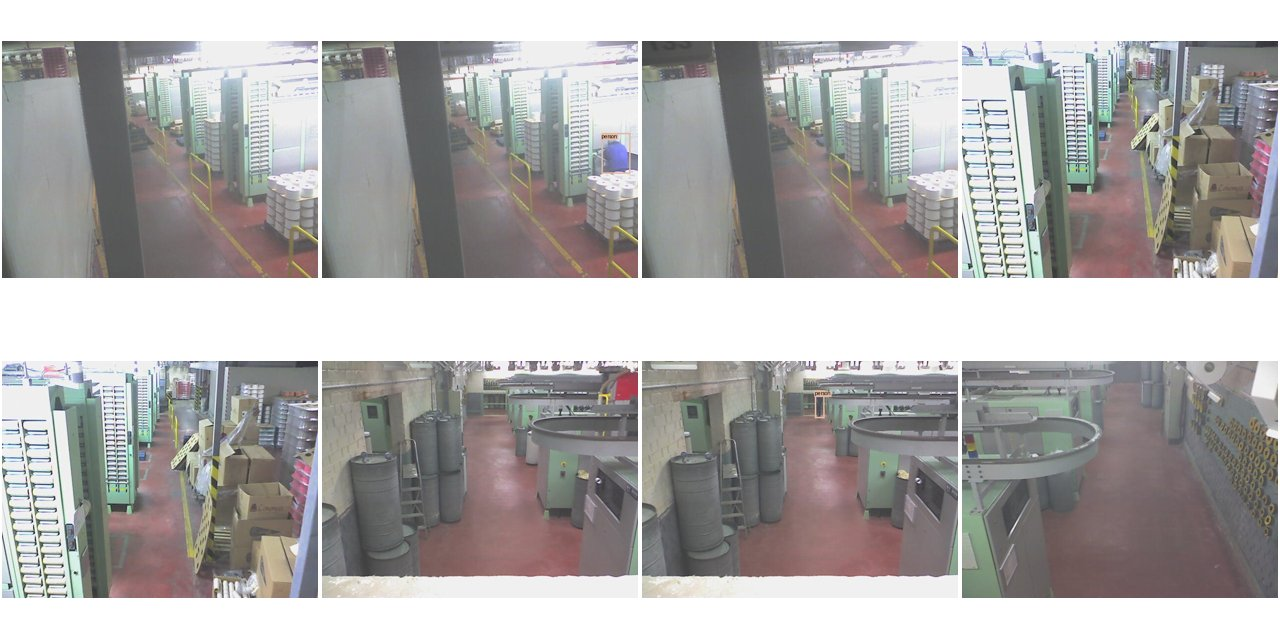

galerie : test


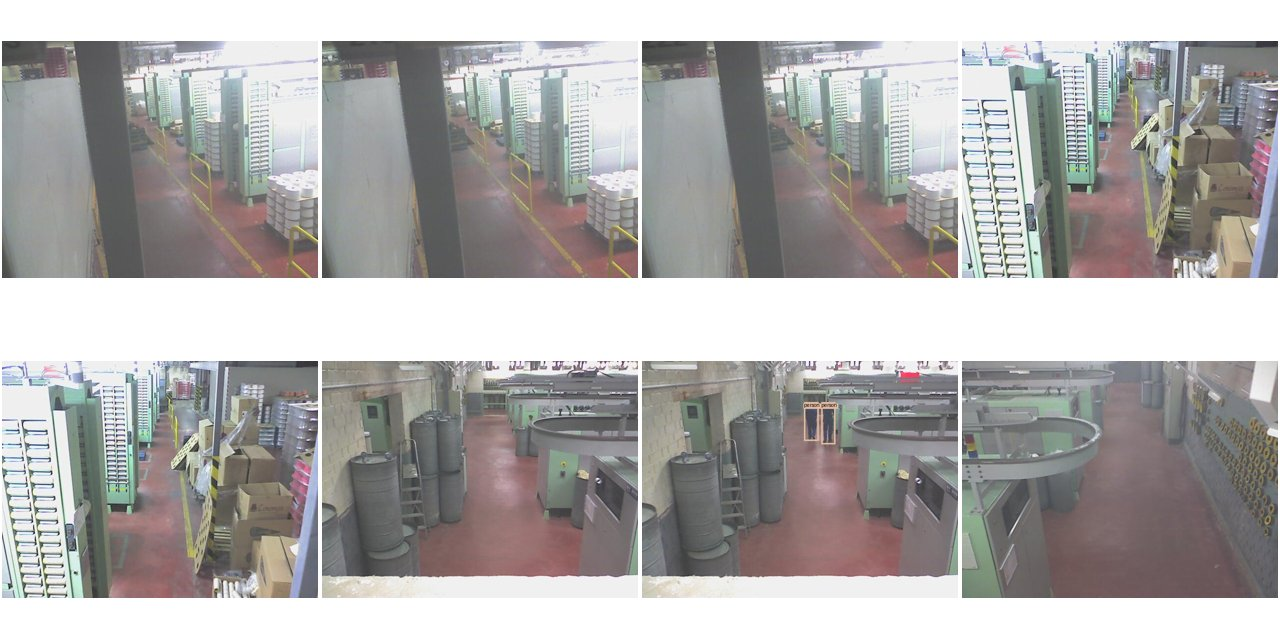

galerie : classes


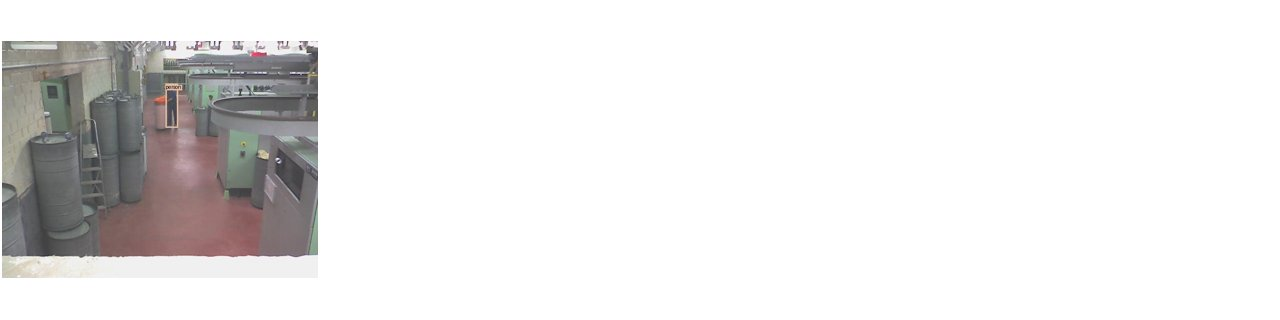

In [4]:
from yolo.data import datasets as D

rows = ["| classe | VOC | COCO |", "|---|---|---|"]
for c in D.DATASETS[DATASET].classes:
    m = [c if DATASET == f else D.MAPPINGS.get((DATASET, f), {}).get(c, "—")
         for f in ("voc", "coco")]
    rows.append(f"| {c} | {m[0]} | {m[1]} |")
display(Markdown("\n".join(rows)))
for g, sheet in STATS.get("galerie", {}).get("planches", {}).items():
    if g != "suspectes":
        print(f"galerie : {g}")
        display(Img(filename=str(Path(OUT, sheet))))

## Comptes et classes (T16.5)

Comptes par split (annotations, split entier), face aux effectifs officiels de la
fiche ; objets par classe et co-occurrence.

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 2 821 | 1 581 | 0 | 1 348 | 1 / 3 | 37,5 % | 13x13 5,1 % · 26x26 0,3 % | 0,00 % | 0 / 0 |
| test | 592 | 343 | 0 | 289 | 1 / 2 | 42,9 % | 13x13 1,7 % · 26x26 0,6 % | 0,87 % | 0 / 0 |
| ensemble | 3 413 | 1 924 | 0 | 1 637 | 1 / 3 | 38,5 % | 13x13 4,5 % · 26x26 0,4 % | 0,16 % | 0 / 0 |

train : 2821 images, 1581 objets ; officiel — / — : ok
test : 592 images, 343 objets ; officiel — / — : ok


| classe | train : objets (images) | test : objets (images) | côté médian (px, letterbox) | petits |
|---|---|---|---|---|
| person | 1 581 (1 473) | 343 (303) | 37 | 38 % |

Rapport classe la plus / la moins fréquente : 1.

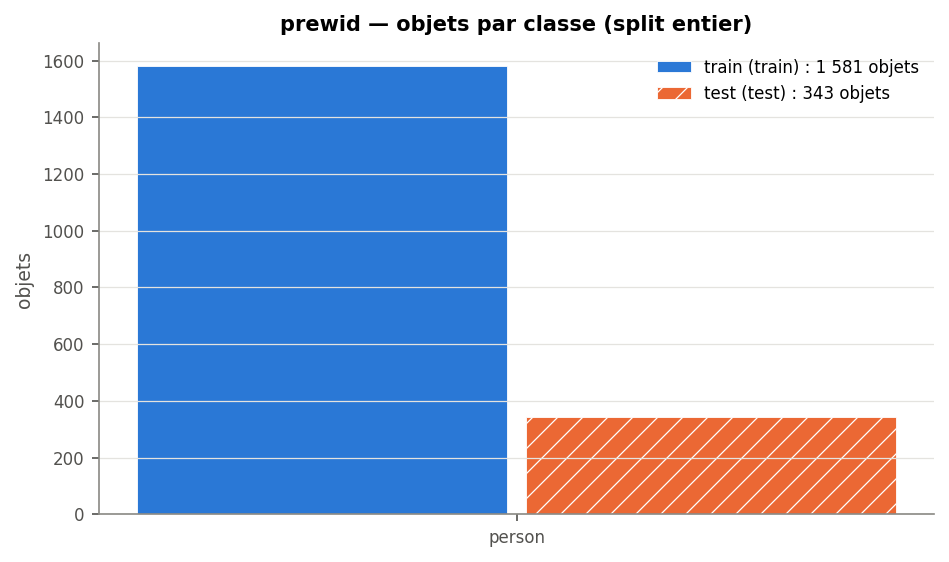

In [5]:
table(DS.md_synthese)
chk = DS.check_official(STATS)
for sp, i, o, (a, b), ok in chk:
    print(f"{sp} : {i} images, {o} objets ; officiel {a or '—'} / {b or '—'} : "
          f"{'ok' if ok else 'écart (voir les notes de la fiche)'}")
table(DS.md_classes)
show("classes")
show("cooccurrence")

## Géométrie des boîtes (T16.6)

Tailles en pixels d'origine et d'entrée (letterbox et stretch à `SIZE`), catégories
COCO avant et après redimensionnement, part des objets plus petits qu'une cellule de
chaque tête, centres des boîtes.

| repère | petits | moyens | grands | côté médian (px) | plus petits qu'une cellule | hauteur < 8 px |
|---|---|---|---|---|---|---|
| image d'origine | 6,3 % | 73,8 % | 20,0 % | 57 | — | — |
| letterbox 416×416 | 38,5 % | 57,5 % | 4,1 % | 37 | 13x13 4,5 % · 26x26 0,4 % | 0,0 % |
| stretch 416×416 | 25,6 % | 65,4 % | 9,0 % | 43 | 13x13 2,2 % · 26x26 0,1 % | 0,0 % |

1 924 objets non-difficult ; pas des têtes : 13x13 → 32 px, 26x26 → 16 px.

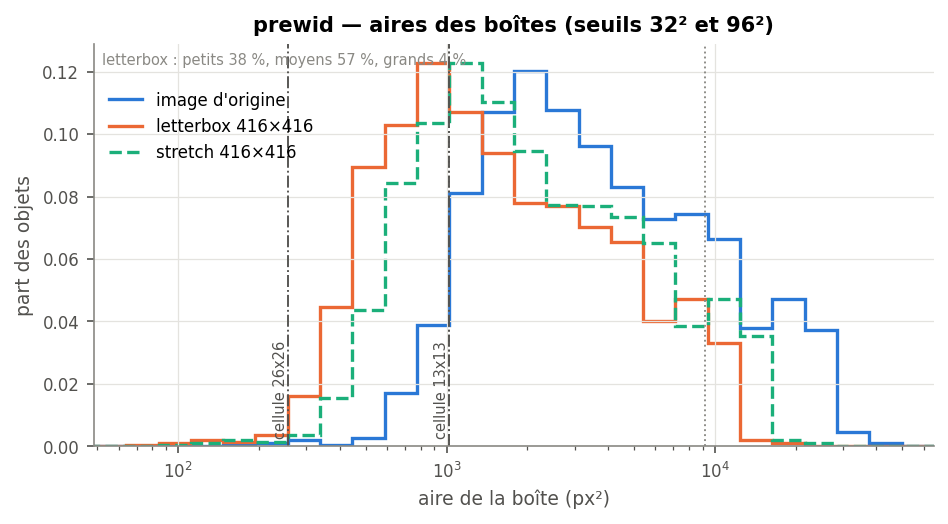

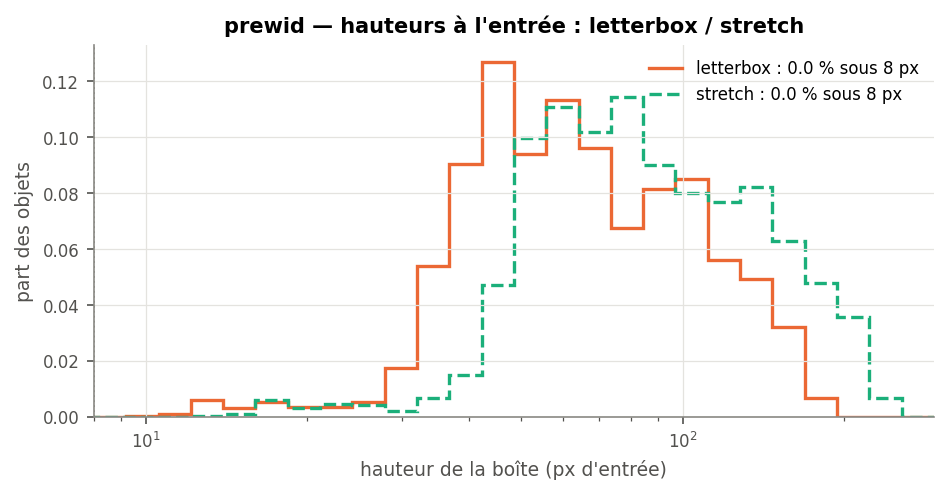

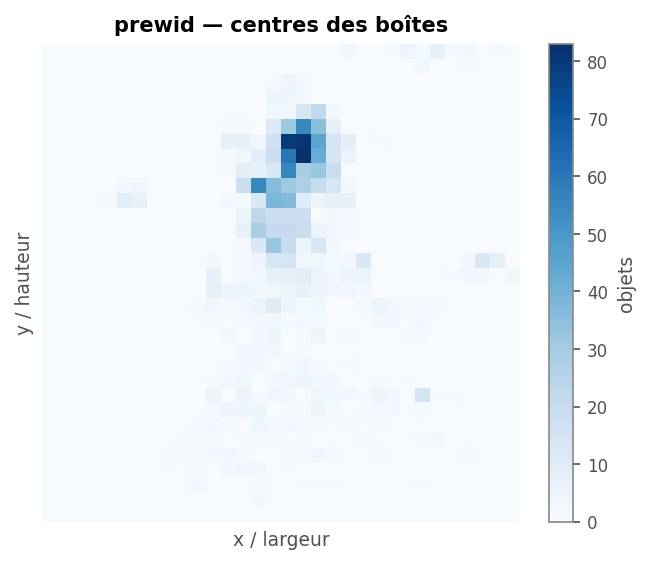

In [6]:
table(DS.md_geometrie)
show("tailles")
show("letterbox_stretch")
show("centres")

## Densité et collisions (T16.7)

Objets par image face aux 256 emplacements de `yolo_post` ; cibles perdues quand deux
objets tombent sur la même cellule et la même ancre (`build_targets`, ancres de `NET`).

| partie | objets/image moy. | méd. | max | > 256 / > 1 024 | cibles perdues | par tête (perdues / objets) | images touchées |
|---|---|---|---|---|---|---|---|
| train | 0,6 | 1 | 3 | 0 / 0 | 0 / 1 581 (0,00 %) | 13x13 : 0 / 406 · 26x26 : 0 / 1 175 | 0 |
| test | 0,6 | 1 | 2 | 0 / 0 | 3 / 343 (0,87 %) | 13x13 : 0 / 90 · 26x26 : 3 / 253 | 3 |
| ensemble | 0,6 | 1 | 3 | 0 / 0 | 3 / 1 924 (0,16 %) | 13x13 : 0 / 496 · 26x26 : 3 / 1 428 | 3 |

Ancres de `build/m11/cfg/tiny-yolov3-prewid.cfg` ; objets non-difficult, comme à l'entraînement.

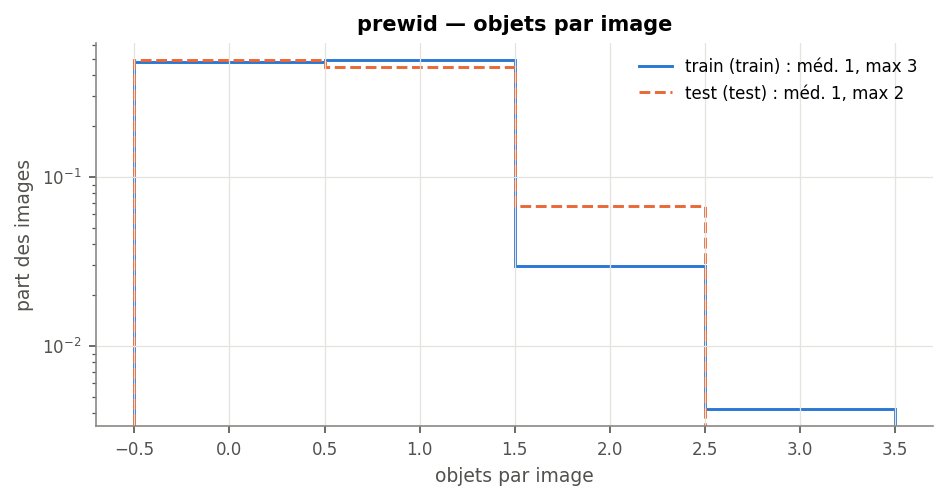

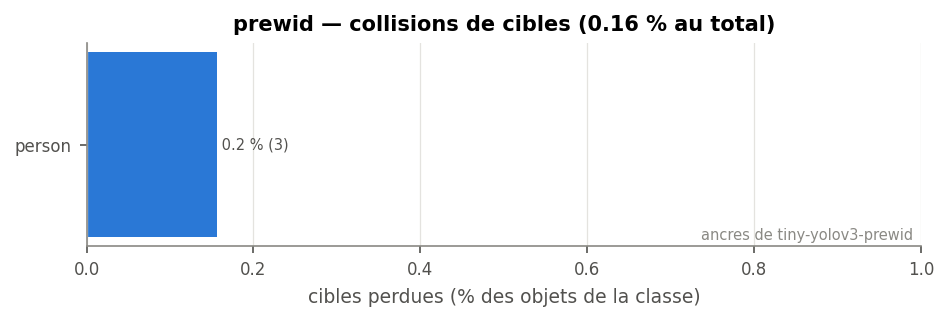

In [7]:
table(DS.md_densite)
show("densite")
show("collisions")

## Images (T16.8)

Résolutions sur le split entier (annotations) ; canaux, intensités et luminance sur
`SAMPLE` images par partie, face à VOC2007 test (échelles INT8 de M4).

| partie | résolutions (3 premières) | distinctes | pixels sur | canaux | moyenne par canal | écart type par canal | luminance moy. | niveaux 8 bits → INT8 |
|---|---|---|---|---|---|---|---|---|
| train | 640×480 (2 821) | 1 | 200 images | 3 | 139,7 / 136,5 / 135,4 | 43,8 / 46,8 / 46,9 | 137,3 | 256 → 128 |
| test | 640×480 (592) | 1 | 200 images | 3 | 140,8 / 137,6 / 136,5 | 44,3 / 47,2 / 47,4 | 138,4 | 256 → 128 |
| ensemble | 640×480 (3 413) | 1 | 200 images | 3 | 140,0 / 136,8 / 135,7 | 43,8 / 46,8 / 46,9 | 137,6 | 256 → 128 |

Référence VOC2007 test (200 images, graine 0) : luminance moyenne 107,7, moyenne par canal 112,1 / 107,1 / 98,5.

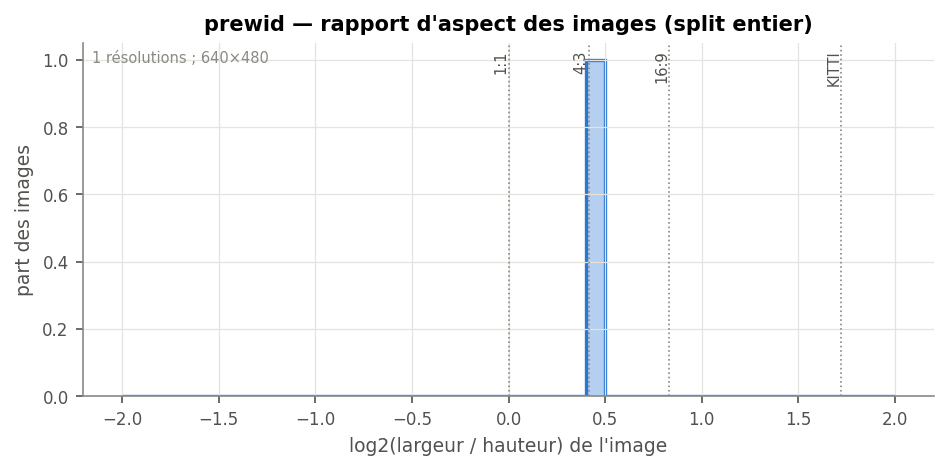

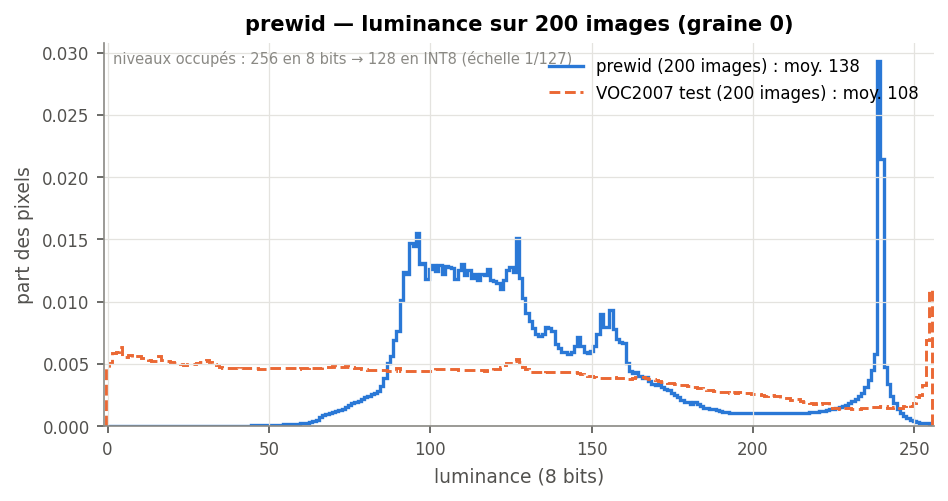

In [8]:
table(DS.md_images)
show("resolutions")
show("intensites")

## Ancres (T16.9)

Boîtes du groupe train en pixels d'entrée letterbox, ancres de la cfg, de VOC, de
COCO et du k-means (`tools/kmeans_anchors.py`, mêmes `--size` et `--seed`).

| ancres | w,h (px à 416×416) | IoU moyenne |
|---|---|---|
| VOC (tiny-yolov2-voc) | `35,38  109,141  212,364  301,164  532,337` | 0,4196 |
| VOC (tiny-yolov3-voc) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,5304 |
| COCO (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,5304 |
| cfg du jeu (tiny-yolov3-prewid) | `15,37  20,56  29,79  40,110  82,88  63,149` | 0,7765 |
| k-means k = 5 (graine 0) | `16,41  24,65  35,100  82,89  59,144` | 0,7557 |
| k-means k = 6 (graine 0) | `15,37  20,56  29,79  40,110  82,88  63,149` | 0,7783 |

1 581 boîtes non-difficult du groupe train, letterbox 416×416.

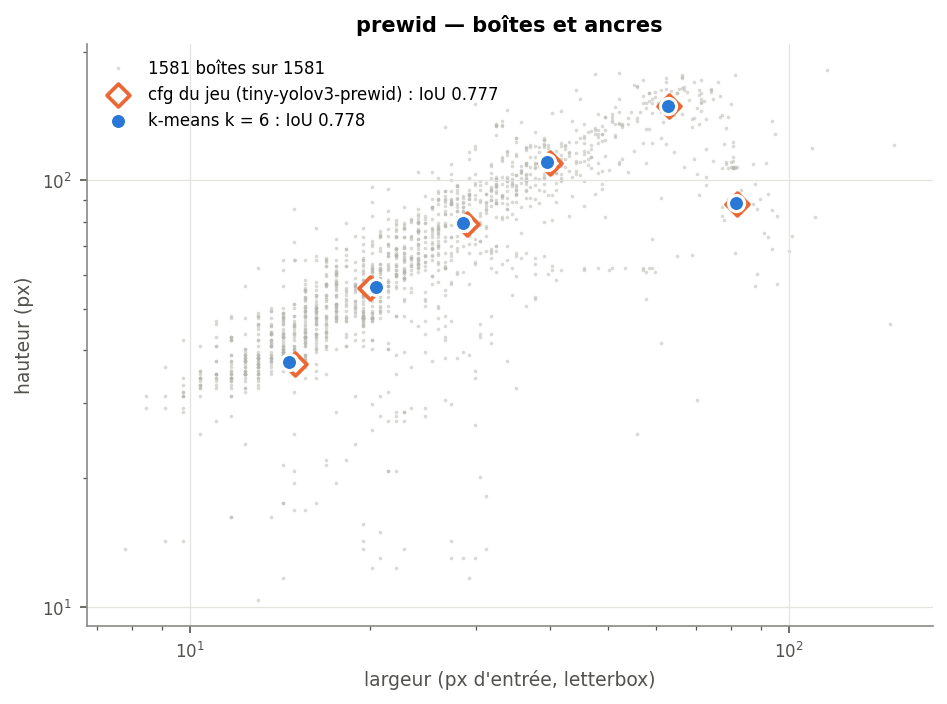

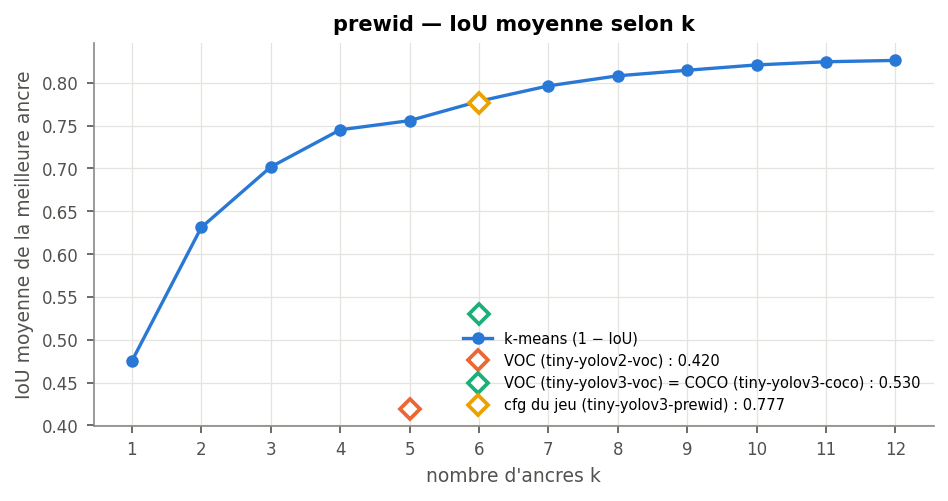

In [9]:
table(DS.md_ancres)
show("ancres")
show("ancres_k")

## Qualité des annotations (T16.10)

Boîtes retirées ou rognées par le chargeur, dégénérées, doublons, régions retirées ;
l'analyse signale, elle ne corrige pas (une correction passe par M11).

In [10]:
table(DS.md_qualite)
sus = DS.whole(STATS).get("qualite", {}).get("suspects", [])
for d in sus:
    print(f"{d['id']} : score {d['score']} (retirées {d['retirées']}, rognées "
          f"{d['rognées']}, dégénérées {d['dégénérées']}, doublons {d['doublons']})")
sheet = STATS.get("galerie", {}).get("planches", {}).get("suspectes")
if sheet:
    display(Img(filename=str(Path(OUT, sheet))))

| partie | retirées (make_sample) | rognées | côté < 2 px (orig. / entrée) | doublons (IoU > 0,95) | régions retirées par le chargeur |
|---|---|---|---|---|---|
| train | — | 0 | 0 / 0 | 0 | — |
| test | — | 0 | 0 / 0 | 0 | — |
| ensemble | — | 0 | 0 / 0 | 0 | — |

## Écart entre splits et couverture hors domaine (T16.11)

Distance en variation totale entre train et test, par grandeur ; part des objets qui
ont une classe VOC ou COCO (ce qu'évaluent les notebooks hors domaine de T14.5).

| grandeur (train ↔ test) | variation totale |
|---|---|
| classes | 0,000 |
| area_in | 0,109 |
| w_in | 0,121 |
| h_in | 0,143 |
| aspect | 0,135 |
| per_image | 0,048 |

| split | classes du modèle | objets couverts | part | évalués (non-difficult) |
|---|---|---|---|---|
| train | VOC | 1 581 | 100,0 % | 1 581 |
| train | COCO | 1 581 | 100,0 % | 1 581 |
| test | VOC | 343 | 100,0 % | 343 |
| test | COCO | 343 | 100,0 % | 343 |

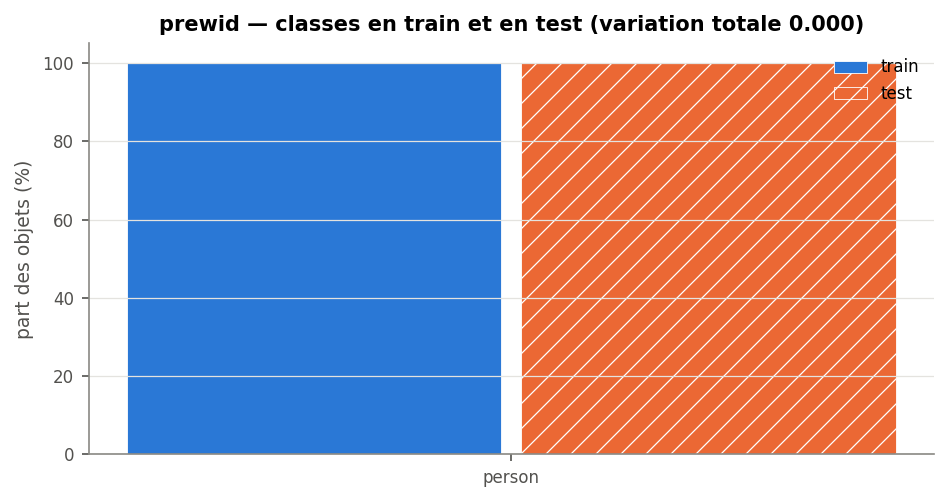

In [11]:
table(DS.md_ecart)
show("ecart")

## Question propre au jeu

How far are the workers from each camera (box height per camera), and what share of the frames is empty? (renvoi : T38.3)

In [12]:
import json
from pathlib import Path
import numpy as np
from yolo.data.datasets import DATA_DIR
root = Path(DATA_ROOT or DATA_DIR / "prewid")
es = {s: json.loads((root / f"annotations_{s}.json").read_text())
      for s in ("train", "val", "test", "lab")}
rows = ["| Camera | Image height | Frames | Empty (train / val / test / lab) | Boxes "
        "| Box height px: q10 / median / q90 | Under 32 px |", "|---|---|---|---|---|---|---|"]
for cam in sorted({e["camera"] for v in es.values() for e in v}):
    fr = {s: [e for e in v if e["camera"] == cam] for s, v in es.items()}
    allf = [e for v in fr.values() for e in v]
    h = np.array([b[3] - b[1] for e in allf for b in e["boxes"]])
    empty = " / ".join(f"{100 * sum(not e['boxes'] for e in v) / len(v):.0f} %"
                       if v else "-" for v in fr.values())
    q = np.quantile(h, [0.1, 0.5, 0.9])
    rows.append(f"| {cam} | {allf[0]['height']} | {len(allf)} | {empty} | {len(h)} "
                f"| {q[0]:.0f} / {q[1]:.0f} / {q[2]:.0f} | {int((h < 32).sum())} |")
display(Markdown("\n".join(rows)))
display(Markdown(DS.md_par_classe(STATS)))

| Camera | Image height | Frames | Empty (train / val / test / lab) | Boxes | Box height px: q10 / median / q90 | Under 32 px |
|---|---|---|---|---|---|---|
| CAM0 | 480 | 1001 | 62 % / 63 % / 64 % / - | 391 | 60 / 89 / 179 | 0 |
| CAM1 | 480 | 1000 | 30 % / 32 % / 31 % / - | 753 | 60 / 111 / 195 | 3 |
| CAM2 | 480 | 1000 | 40 % / 41 % / 41 % / - | 657 | 48 / 71 / 107 | 37 |
| CAM3 | 480 | 1002 | 59 % / 59 % / 60 % / - | 447 | 87 / 152 / 240 | 0 |
| CAMLAB01 | 1080 | 3000 | - / - / - / 48 % | 1574 | 115 / 392 / 719 | 7 |

| classe | objets (test, non-difficult) | part | côté médian (px) | petits | cibles perdues |
|---|---|---|---|---|---|
| person | 343 | 100,0 % | 35 | 43 % | 0,87 % |

## Résumé

In [13]:
table(DS.md_synthese)
print(f"sorties : {OUT}/ (stats.json, stats.md, figures/, galerie/) ; "
      f"révision {TRACE['rev']}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 2 821 | 1 581 | 0 | 1 348 | 1 / 3 | 37,5 % | 13x13 5,1 % · 26x26 0,3 % | 0,00 % | 0 / 0 |
| test | 592 | 343 | 0 | 289 | 1 / 2 | 42,9 % | 13x13 1,7 % · 26x26 0,6 % | 0,87 % | 0 / 0 |
| ensemble | 3 413 | 1 924 | 0 | 1 637 | 1 / 3 | 38,5 % | 13x13 4,5 % · 26x26 0,4 % | 0,16 % | 0 / 0 |

sorties : build/notebooks/prewid/stats/ (stats.json, stats.md, figures/, galerie/) ; révision fba540c
commandes équivalentes :
  python tools/data_stats.py --dataset prewid --size 416 --resize letterbox --net build/m11/cfg/tiny-yolov3-prewid.cfg --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/prewid/stats
